# AI-Powered E-Commerce Intelligence System

## 1. Project Introduction

This project focuses on analyzing e-commerce sales data, understanding customer behavior, predicting product demand, and generating business insights using Machine Learning.

## 2. Project Objectives

- Analyze sales performance.
- Understand customer purchasing behavior.
- Identify top-performing products.
- Predict future product demand.
- Forecast business revenue.

In [4]:
import pandas as pd

file_path = "../data/raw/Online Retail.xlsx"

df = pd.read_excel(file_path)

df.head()



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (541909, 8)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268


In [6]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

missing_data

,Missing Values,Percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


In [7]:
duplicates = df[df.duplicated()]

duplicates.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom


In [8]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

Shape after removing duplicates: (536641, 8)
Remaining duplicates: 0


In [9]:
df[df["Description"].isnull()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom


In [10]:
df = df.dropna(subset=["Description"])

print("Shape after removing missing descriptions:", df.shape)

print("Missing descriptions:", df["Description"].isnull().sum())

Shape after removing missing descriptions: (535187, 8)
Missing descriptions: 0


In [11]:
print("Missing CustomerID:", df["CustomerID"].isnull().sum())

print("Percentage:", 
      (df["CustomerID"].isnull().sum() / len(df)) * 100)

Missing CustomerID: 133583
Percentage: 24.96006068906756


In [12]:
# Preserve all sales records
sales_df = df.copy()

# Create customer analysis dataset
customer_df = df.dropna(subset=["CustomerID"]).copy()

print("Sales Dataset:", sales_df.shape)
print("Customer Dataset:", customer_df.shape)
print("Missing CustomerID:", customer_df["CustomerID"].isnull().sum())

Sales Dataset: (535187, 8)
Customer Dataset: (401604, 8)
Missing CustomerID: 0


In [13]:
print("Negative Quantity:", (sales_df["Quantity"] < 0).sum())

print("Zero Quantity:", (sales_df["Quantity"] == 0).sum())

print("Negative UnitPrice:", (sales_df["UnitPrice"] < 0).sum())

print("Zero UnitPrice:", (sales_df["UnitPrice"] == 0).sum())

Negative Quantity: 9725
Zero Quantity: 0
Negative UnitPrice: 2
Zero UnitPrice: 1056


In [14]:
sales_df[sales_df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [15]:
cancelled_orders = sales_df[
    sales_df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancelled Transactions:", len(cancelled_orders))

print("Total Transactions:", len(sales_df))

Cancelled Transactions: 9251
Total Transactions: 535187


In [16]:
valid_sales_df = sales_df[
    ~sales_df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Valid Sales Records:", len(valid_sales_df))

print("Negative Quantity Remaining:",
      (valid_sales_df["Quantity"] < 0).sum())

Valid Sales Records: 525936
Negative Quantity Remaining: 474


In [17]:
remaining_returns = valid_sales_df[
    valid_sales_df["Quantity"] < 0
]

remaining_returns.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
7313,537032,21275,?,-30,2010-12-03 16:50:00,0.0,NaN,United Kingdom
13217,537425,84968F,check,-20,2010-12-06 15:35:00,0.0,NaN,United Kingdom
13218,537426,84968E,check,-35,2010-12-06 15:36:00,0.0,NaN,United Kingdom
13264,537432,35833G,damages,-43,2010-12-06 16:10:00,0.0,NaN,United Kingdom
21338,538072,22423,faulty,-13,2010-12-09 14:10:00,0.0,NaN,United Kingdom
21518,538090,20956,?,-723,2010-12-09 14:48:00,0.0,NaN,United Kingdom
22296,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.0,NaN,United Kingdom
22297,538162,46000M,Dotcom sales,-100,2010-12-09 17:25:00,0.0,NaN,United Kingdom
42564,540010,22501,reverse 21/5/10 adjustment,-100,2011-01-04 11:13:00,0.0,NaN,United Kingdom
42566,540012,22502,reverse 21/5/10 adjustment,-100,2011-01-04 11:14:00,0.0,NaN,United Kingdom


In [18]:
clean_sales_df = valid_sales_df[
    valid_sales_df["Quantity"] > 0
].copy()

print("Clean Sales Dataset:", clean_sales_df.shape)

print("Negative Quantity:",
      (clean_sales_df["Quantity"] < 0).sum())

print("Zero Quantity:",
      (clean_sales_df["Quantity"] == 0).sum())

Clean Sales Dataset: (525462, 8)
Negative Quantity: 0
Zero Quantity: 0


In [19]:
zero_price = clean_sales_df[
    clean_sales_df["UnitPrice"] == 0
]

print("Zero UnitPrice Records:", len(zero_price))

zero_price.head(10)

Zero UnitPrice Records: 582


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
6391,536941,22734,amazon,20,2010-12-03 12:08:00,0.0,NaN,United Kingdom
6392,536942,22139,amazon,15,2010-12-03 12:08:00,0.0,NaN,United Kingdom
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
14335,537534,85064,CREAM SWEETHEART LETTER RACK,1,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14336,537534,84832,ZINC WILLIE WINKIE CANDLE STICK,1,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14337,537534,84692,BOX OF 24 COCKTAIL PARASOLS,2,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14338,537534,48184,DOORMAT ENGLISH ROSE,3,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14339,537534,48111,DOORMAT 3 SMILEY CATS,1,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14340,537534,22697,GREEN REGENCY TEACUP AND SAUCER,1,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14341,537534,22682,FRENCH BLUE METAL DOOR SIGN 7,1,2010-12-07 11:48:00,0.0,NaN,United Kingdom


In [20]:
print("Zero Price Records:", len(zero_price))

print("Percentage:",
      (len(zero_price) / len(clean_sales_df)) * 100)

print("Unique Descriptions:")
print(zero_price["Description"].value_counts().head(15))

Zero Price Records: 582
Percentage: 0.11075967434372039
Unique Descriptions:
Description
check                              39
found                              25
adjustment                         14
FRENCH BLUE METAL DOOR SIGN 1       9
amazon                              8
FRENCH BLUE METAL DOOR SIGN 8       8
Found                               8
FRENCH BLUE METAL DOOR SIGN 4       7
FRENCH BLUE METAL DOOR SIGN No      7
OWL DOORSTOP                        7
FRENCH BLUE METAL DOOR SIGN 3       7
RECIPE BOX PANTRY YELLOW DESIGN     7
Amazon                              7
FRENCH BLUE METAL DOOR SIGN 7       6
FRENCH BLUE METAL DOOR SIGN 5       6
Name: count, dtype: int64


In [21]:
final_sales_df = clean_sales_df[
    clean_sales_df["UnitPrice"] > 0
].copy()

print("Final Sales Dataset:", final_sales_df.shape)

print("Zero UnitPrice:",
      (final_sales_df["UnitPrice"] == 0).sum())

print("Negative UnitPrice:",
      (final_sales_df["UnitPrice"] < 0).sum())

Final Sales Dataset: (524878, 8)
Zero UnitPrice: 0
Negative UnitPrice: 0


In [22]:
final_sales_df["Revenue"] = (
    final_sales_df["Quantity"] * final_sales_df["UnitPrice"]
)

print(final_sales_df[[
    "Description", "Quantity", "UnitPrice", "Revenue"
]].head())

print("\nTotal Revenue:",
      final_sales_df["Revenue"].sum())

                           Description  Quantity  UnitPrice  Revenue
0   WHITE HANGING HEART T-LIGHT HOLDER         6       2.55    15.30
1                  WHITE METAL LANTERN         6       3.39    20.34
2       CREAM CUPID HEARTS COAT HANGER         8       2.75    22.00
3  KNITTED UNION FLAG HOT WATER BOTTLE         6       3.39    20.34
4       RED WOOLLY HOTTIE WHITE HEART.         6       3.39    20.34

Total Revenue: 10642110.804000001


In [23]:
country_revenue = (
    final_sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

country_revenue.head(10)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

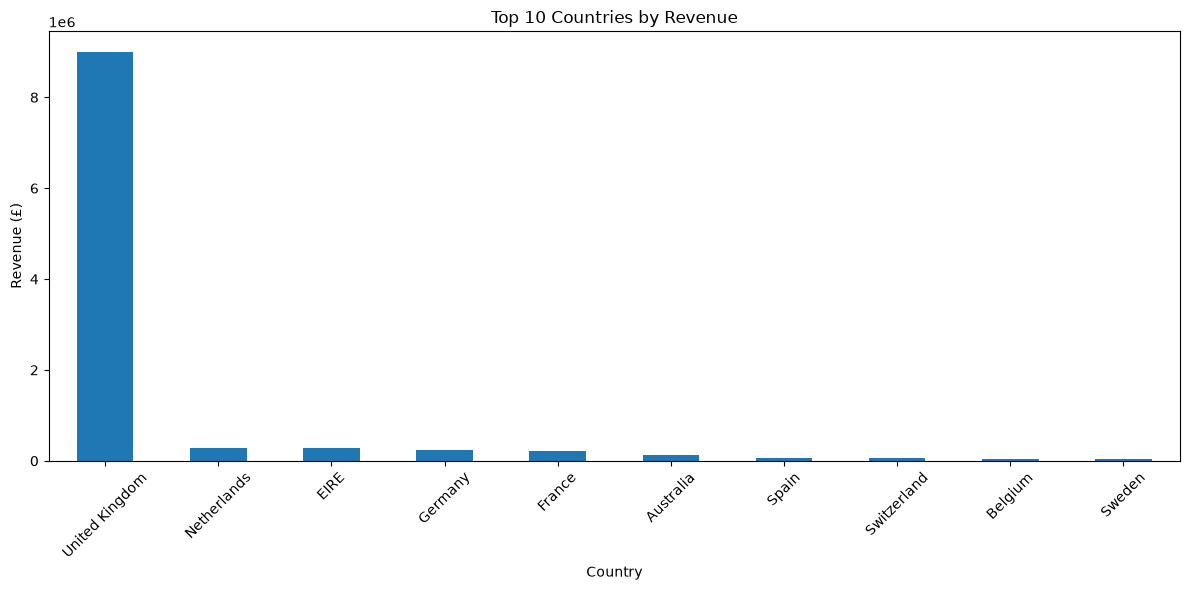

In [24]:
import matplotlib.pyplot as plt

top_10 = country_revenue.head(10)

plt.figure(figsize=(12, 6))

top_10.plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [25]:
top_products = (
    final_sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

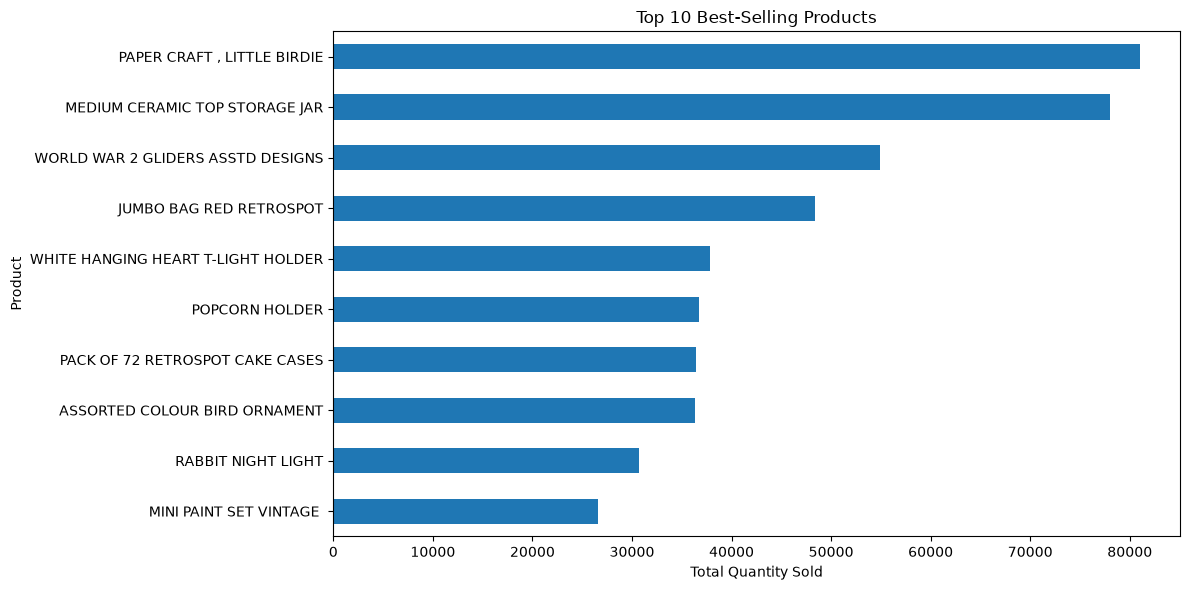

In [26]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [27]:
top_revenue_products = (
    final_sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_revenue_products

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

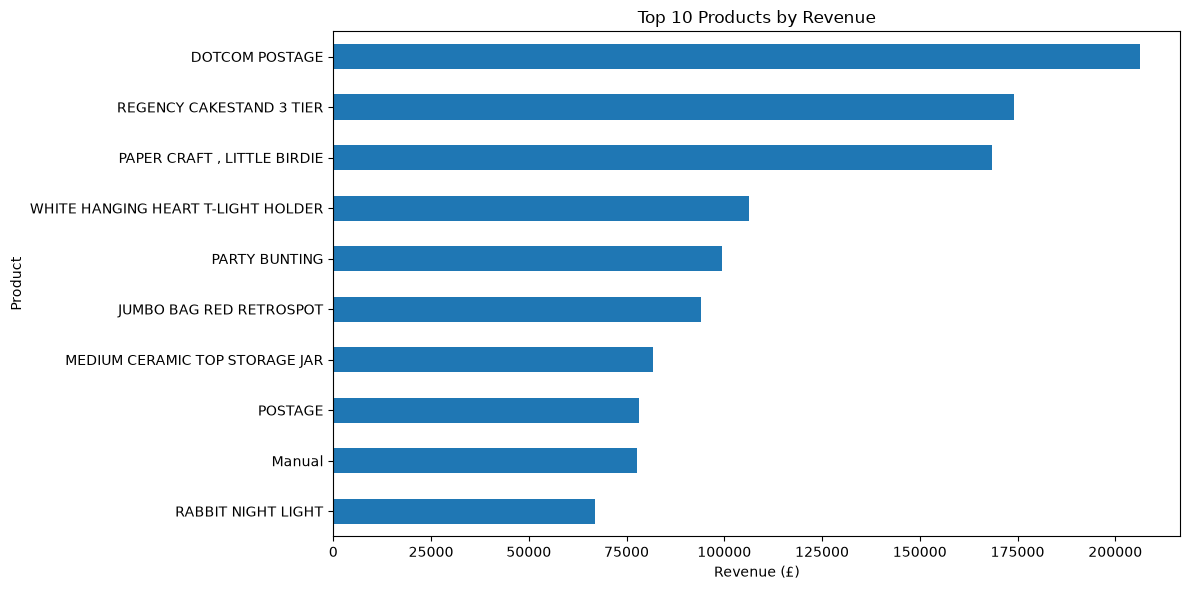

In [28]:
plt.figure(figsize=(12, 6))

top_revenue_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [29]:
final_sales_df["Month"] = (
    final_sales_df["InvoiceDate"].dt.to_period("M")
)

monthly_revenue = (
    final_sales_df.groupby("Month")["Revenue"]
    .sum()
)

monthly_revenue

Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

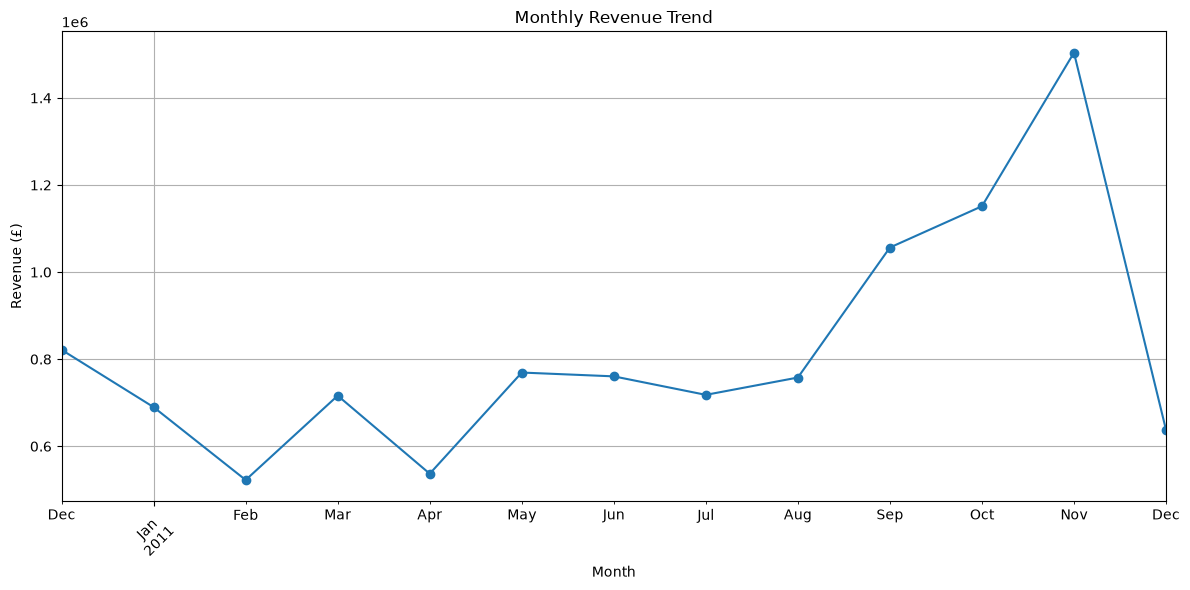

In [30]:
plt.figure(figsize=(12, 6))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [31]:
customer_revenue = (
    final_sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

customer_revenue

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

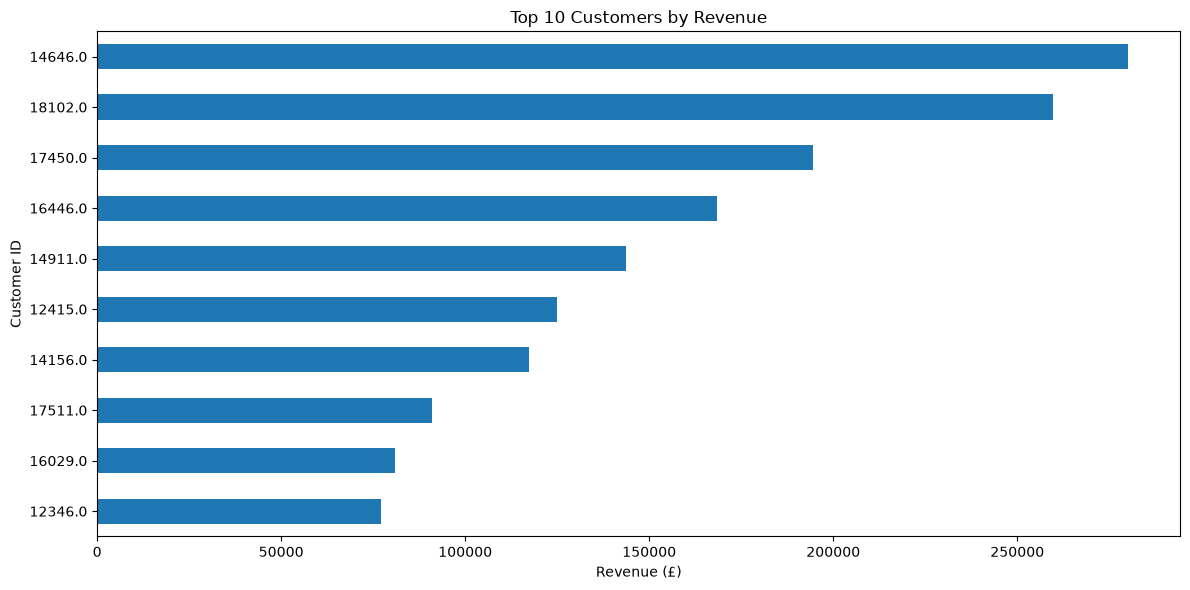

In [32]:
plt.figure(figsize=(12, 6))

customer_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [33]:
customer_orders = (
    final_sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

customer_orders.head(10)

CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

In [34]:
import pandas as pd

snapshot_date = final_sales_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = final_sales_df.dropna(subset=["CustomerID"]).groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "Revenue": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [35]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346.0,326,1,77183.60,1,1,5
12347.0,2,7,4310.00,5,5,5
12348.0,75,4,1797.24,2,4,4
12349.0,19,1,1757.55,4,1,4
12350.0,310,1,334.40,1,1,2


In [36]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"
    elif row["R_Score"] >= 4:
        return "Recent Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    else:
        return "Others"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

rfm[["Recency", "Frequency", "Monetary", "RFM_Score", "Segment"]].head(10)

,Recency,Frequency,Monetary,RFM_Score,Segment
CustomerID,,,,,
12346.0,326,1,77183.60,115,Others
12347.0,2,7,4310.00,555,Champions
12348.0,75,4,1797.24,244,At Risk
12349.0,19,1,1757.55,414,Recent Customers
12350.0,310,1,334.40,112,Others
12352.0,36,8,2506.04,355,Loyal Customers
12353.0,204,1,89.00,111,Others
12354.0,232,1,1079.40,114,Others
12355.0,214,1,459.40,112,Others


In [37]:
segment_counts = rfm["Segment"].value_counts()

print(segment_counts)

Segment
Others              1425
Loyal Customers     1000
Champions            942
At Risk              661
Recent Customers     310
Name: count, dtype: int64


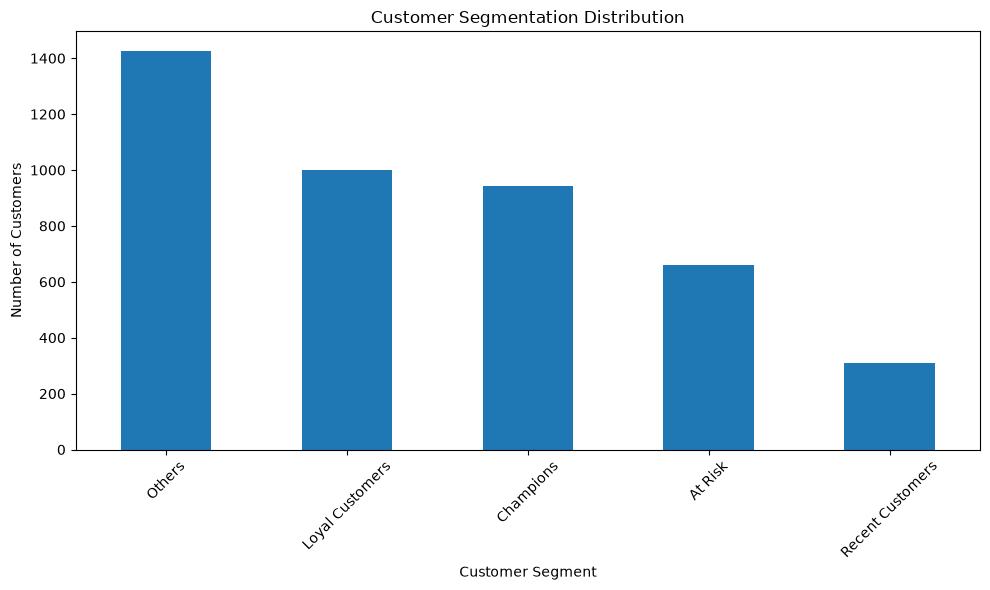

In [38]:
plt.figure(figsize=(10, 6))

segment_counts.plot(kind="bar")

plt.title("Customer Segmentation Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [39]:
final_sales_df["YearMonth"] = (
    final_sales_df["InvoiceDate"].dt.to_period("M")
)

monthly_demand = (
    final_sales_df.groupby(["YearMonth", "StockCode"])["Quantity"]
    .sum()
    .reset_index()
)

monthly_demand.head(10)

,YearMonth,StockCode,Quantity
0,2010-12,10002,251
1,2010-12,10120,16
2,2010-12,10125,154
3,2010-12,10133,130
4,2010-12,10135,411
5,2010-12,11001,74
6,2010-12,15034,45
7,2010-12,15036,161
8,2010-12,15039,20
9,2010-12,16008,14


In [40]:
product_demand = (
    monthly_demand.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

product_demand.head(10)

StockCode
23843     80995
23166     78033
22197     56898
84077     54951
85099B    48371
85123A    37641
21212     36396
84879     36362
23084     30739
22492     26633
Name: Quantity, dtype: int64

In [41]:
selected_product = "23843"

product_data = monthly_demand[
    monthly_demand["StockCode"].astype(str) == selected_product
].copy()

product_data = product_data.sort_values("YearMonth")

product_data

,YearMonth,StockCode,Quantity
33443,2011-12,23843,80995


In [42]:
product_month_counts = (
    monthly_demand.groupby("StockCode")["YearMonth"]
    .nunique()
    .sort_values(ascending=False)
)

product_month_counts.head(10)

StockCode
10135    13
C2       13
11001    13
35924    13
35961    13
35970    13
35971    13
37340    13
37446    13
37447    13
Name: YearMonth, dtype: int64

In [43]:
selected_product = "10135"

product_data = monthly_demand[
    monthly_demand["StockCode"].astype(str) == selected_product
].copy()

product_data = product_data.sort_values("YearMonth")

product_data

,YearMonth,StockCode,Quantity
4,2010-12,10135,411
2791,2011-01,10135,613
5365,2011-02,10135,272
7763,2011-03,10135,118
10265,2011-04,10135,30
12724,2011-05,10135,13
15182,2011-06,10135,55
17808,2011-07,10135,177
20478,2011-08,10135,151
23074,2011-09,10135,70


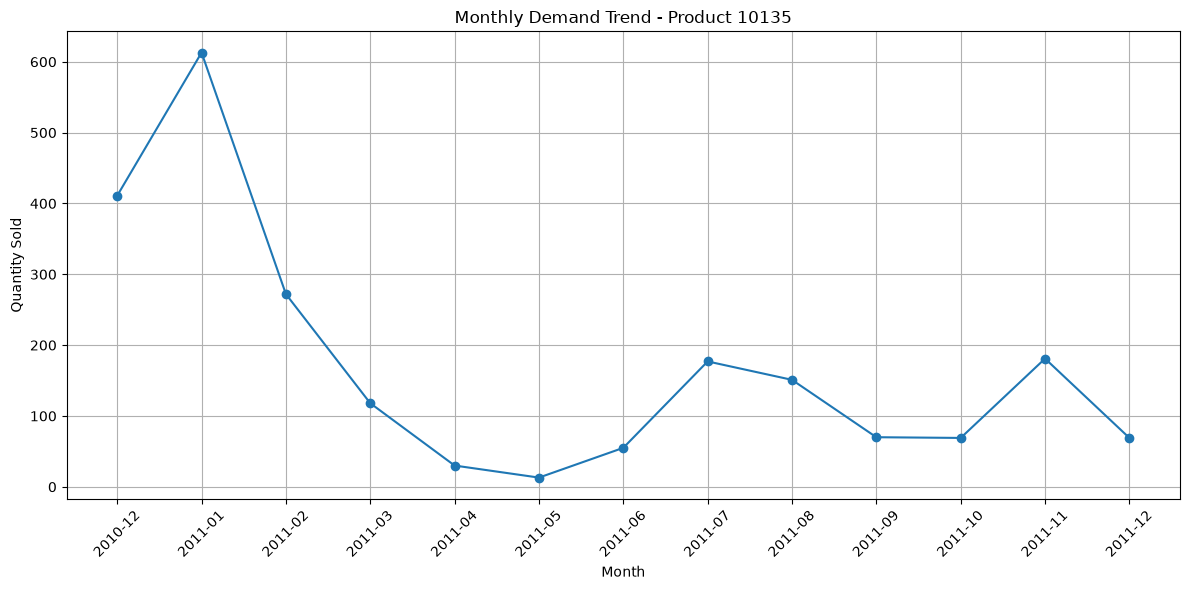

In [44]:
product_data["YearMonth"] = (
    product_data["YearMonth"].astype(str)
)

plt.figure(figsize=(12, 6))

plt.plot(
    product_data["YearMonth"],
    product_data["Quantity"],
    marker="o"
)

plt.title("Monthly Demand Trend - Product 10135")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [45]:
# Create a copy of product data
forecast_df = product_data.copy()

# Convert YearMonth into datetime
forecast_df["YearMonth"] = pd.to_datetime(
    forecast_df["YearMonth"]
)

# Extract numerical time features
forecast_df["Month"] = forecast_df["YearMonth"].dt.month
forecast_df["Year"] = forecast_df["YearMonth"].dt.year

# Create previous month demand feature
forecast_df["Previous_Month_Demand"] = (
    forecast_df["Quantity"].shift(1)
)

# Remove first row containing missing lag value
forecast_df = forecast_df.dropna()

forecast_df

,YearMonth,StockCode,Quantity,Month,Year,Previous_Month_Demand
2791,2011-01-01,10135,613,1,2011,411.0
5365,2011-02-01,10135,272,2,2011,613.0
7763,2011-03-01,10135,118,3,2011,272.0
10265,2011-04-01,10135,30,4,2011,118.0
12724,2011-05-01,10135,13,5,2011,30.0
15182,2011-06-01,10135,55,6,2011,13.0
17808,2011-07-01,10135,177,7,2011,55.0
20478,2011-08-01,10135,151,8,2011,177.0
23074,2011-09-01,10135,70,9,2011,151.0
25806,2011-10-01,10135,69,10,2011,70.0


In [46]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Select features and target
X = forecast_df[["Month", "Year", "Previous_Month_Demand"]]
y = forecast_df["Quantity"]

# Chronological train-test split
X_train = X.iloc[:-3]
X_test = X.iloc[-3:]

y_train = y.iloc[:-3]
y_test = y.iloc[-3:]

# Train Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)

Mean Absolute Error: 51.31999999999999
Root Mean Squared Error: 53.81855442131458


In [47]:
comparison_df = pd.DataFrame({
    "Actual Demand": y_test.values,
    "Predicted Demand": y_pred.round(2)
})

comparison_df

,Actual Demand,Predicted Demand
0,69,106.88
1,181,106.88
2,69,110.96


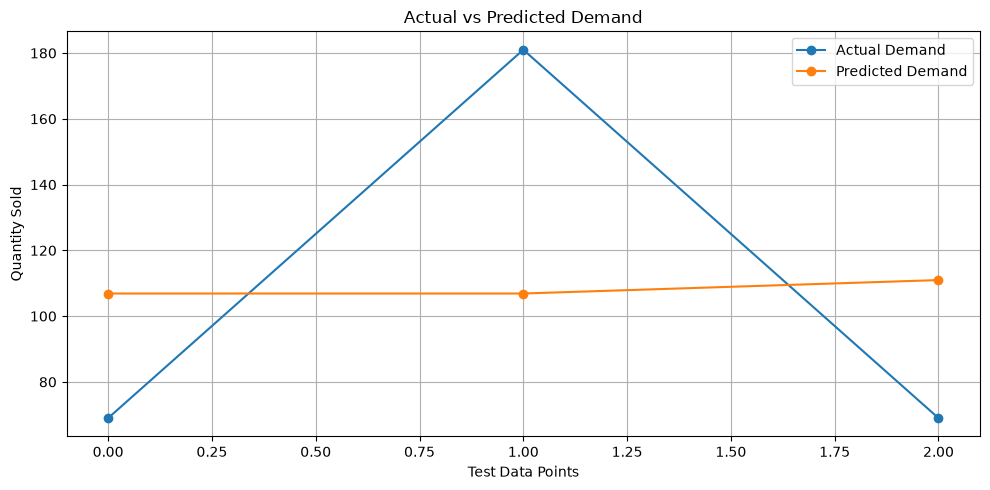

In [48]:
plt.figure(figsize=(10, 5))

plt.plot(y_test.values, marker="o", label="Actual Demand")
plt.plot(y_pred, marker="o", label="Predicted Demand")

plt.title("Actual vs Predicted Demand")
plt.xlabel("Test Data Points")
plt.ylabel("Quantity Sold")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

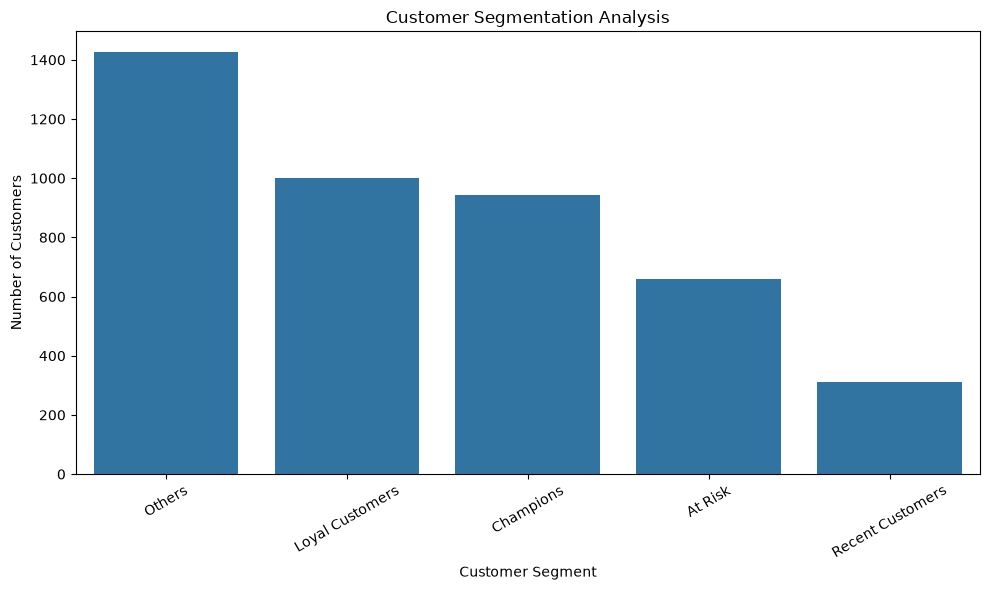

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.countplot(
    data=rfm,
    x="Segment",
    order=rfm["Segment"].value_counts().index
)

plt.title("Customer Segmentation Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

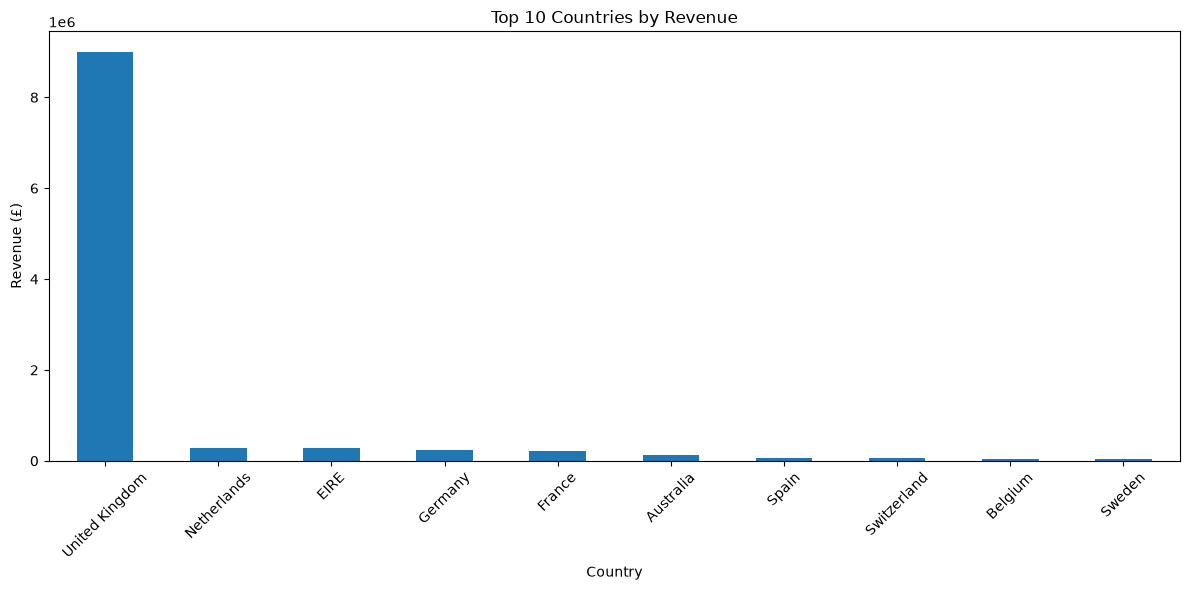

In [50]:
country_revenue = (
    final_sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

country_revenue.plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:
monthly_revenue = (
    final_sales_df.groupby(
        final_sales_df["InvoiceDate"].dt.to_period("M")
    )["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue.columns = ["YearMonth", "Revenue"]

monthly_revenue

,YearMonth,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


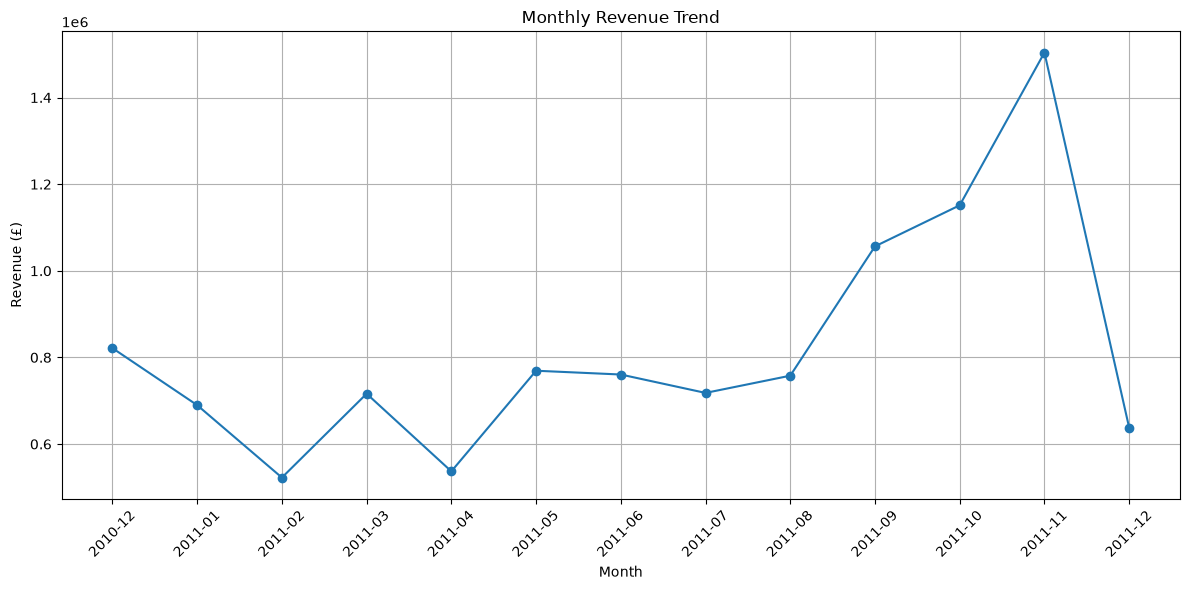

In [52]:
monthly_revenue["YearMonth"] = (
    monthly_revenue["YearMonth"].astype(str)
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["YearMonth"],
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [53]:
# Create a copy of monthly revenue data
revenue_forecast_df = monthly_revenue.copy()

# Convert YearMonth into datetime
revenue_forecast_df["YearMonth"] = pd.to_datetime(
    revenue_forecast_df["YearMonth"]
)

# Extract month and year
revenue_forecast_df["Month"] = (
    revenue_forecast_df["YearMonth"].dt.month
)

revenue_forecast_df["Year"] = (
    revenue_forecast_df["YearMonth"].dt.year
)

# Create previous month's revenue
revenue_forecast_df["Previous_Month_Revenue"] = (
    revenue_forecast_df["Revenue"].shift(1)
)

# Remove first row with missing value
revenue_forecast_df = revenue_forecast_df.dropna()

revenue_forecast_df

,YearMonth,Revenue,Month,Year,Previous_Month_Revenue
1,2011-01-01,689811.610,1,2011,821452.730
2,2011-02-01,522545.560,2,2011,689811.610
3,2011-03-01,716215.260,3,2011,522545.560
4,2011-04-01,536968.491,4,2011,716215.260
5,2011-05-01,769296.610,5,2011,536968.491
6,2011-06-01,760547.010,6,2011,769296.610
7,2011-07-01,718076.121,7,2011,760547.010
8,2011-08-01,757841.380,8,2011,718076.121
9,2011-09-01,1056435.192,9,2011,757841.380
10,2011-10-01,1151263.730,10,2011,1056435.192


In [54]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Select features and target
X = revenue_forecast_df[
    ["Month", "Year", "Previous_Month_Revenue"]
]

y = revenue_forecast_df["Revenue"]

# Chronological train-test split
X_train = X.iloc[:-3]
X_test = X.iloc[-3:]

y_train = y.iloc[:-3]
y_test = y.iloc[-3:]

# Create Random Forest model
revenue_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train model
revenue_model.fit(X_train, y_train)

# Predict revenue
revenue_pred = revenue_model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, revenue_pred)
rmse = np.sqrt(mean_squared_error(y_test, revenue_pred))

print("Revenue MAE:", mae)
print("Revenue RMSE:", rmse)

Revenue MAE: 349598.3688133329
Revenue RMSE: 378309.4576245364


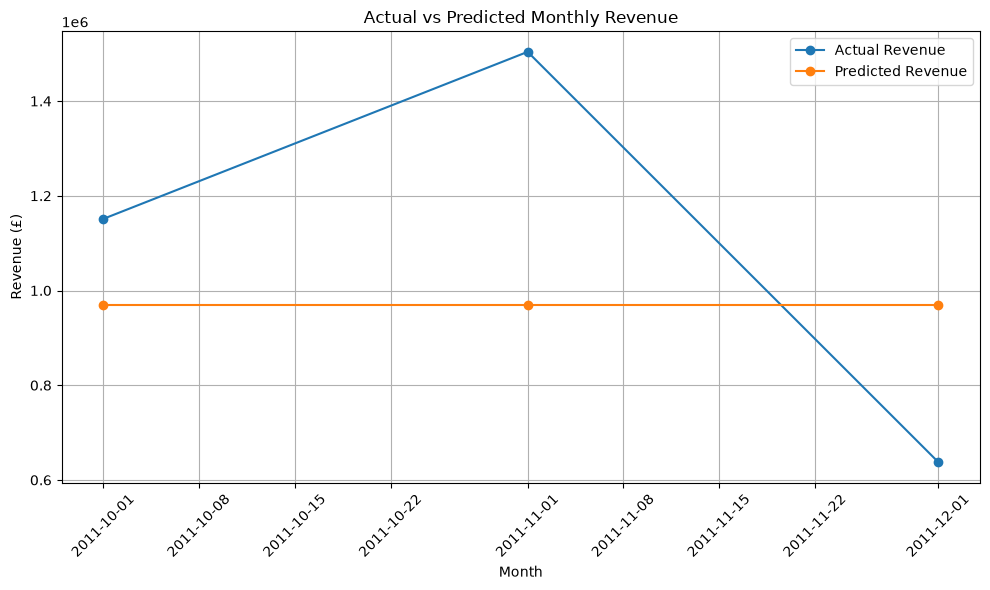

In [55]:
plt.figure(figsize=(10, 6))

plt.plot(
    revenue_forecast_df["YearMonth"].iloc[-3:],
    y_test.values,
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    revenue_forecast_df["YearMonth"].iloc[-3:],
    revenue_pred,
    marker="o",
    label="Predicted Revenue"
)

plt.title("Actual vs Predicted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [56]:
from sqlalchemy import create_engine

# Create SQLite database
engine = create_engine("sqlite:///ecommerce_intelligence.db")

print("Database connection successful!")

Database connection successful!


In [58]:
# Create a copy for SQL storage
sql_sales_df = final_sales_df.copy()

# Convert Period columns into strings
for col in sql_sales_df.columns:
    if isinstance(sql_sales_df[col].dtype, pd.PeriodDtype):
        sql_sales_df[col] = sql_sales_df[col].astype(str)

print("Data prepared for SQL storage!")

Data prepared for SQL storage!


In [59]:
sql_sales_df.to_sql(
    name="sales",
    con=engine,
    if_exists="replace",
    index=False
)

print("Sales data successfully stored in database!")

Sales data successfully stored in database!


In [61]:
from sqlalchemy import text

with engine.connect() as connection:
    result = connection.execute(
        text("SELECT COUNT(*) FROM sales")
    )

    total_records = result.scalar()

print("Total Records in SQL Database:", total_records)

Total Records in SQL Database: 0


In [62]:
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT COUNT(*) FROM sales")
    )
    total_records = result.scalar_one()

print("Total Records in SQL Database:", total_records)

Total Records in SQL Database: 0


In [63]:
print("Database:", engine.url)

print("DataFrame rows:", len(sql_sales_df))

print("Table exists:")
print(pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table'",
    engine
))

Database: sqlite:///ecommerce_intelligence.db
DataFrame rows: 524878
Table exists:
    name
0  sales


In [64]:
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT COUNT(*) FROM sales")
    )
    print("SQL Table Records:", result.scalar())

SQL Table Records: 0


In [65]:
# Insert sales data into SQLite
sql_sales_df.to_sql(
    name="sales",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=10000
)

# Immediately verify inserted records
with engine.connect() as connection:
    count = connection.execute(
        text("SELECT COUNT(*) FROM sales")
    ).scalar_one()

print("Total Records in SQL Database:", count)

Total Records in SQL Database: 524878


In [66]:
query = """
SELECT
    Country,
    ROUND(SUM(Revenue), 2) AS Total_Revenue
FROM sales
GROUP BY Country
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

top_countries = pd.read_sql(query, engine)

top_countries

,Country,Total_Revenue
0,United Kingdom,9001744.09
1,Netherlands,285446.34
2,EIRE,283140.52
3,Germany,228678.40
4,France,209625.37
5,Australia,138453.81
6,Spain,61558.56
7,Switzerland,57067.60
8,Belgium,41196.34
9,Sweden,38367.83


In [67]:
query = """
SELECT
    CustomerID,
    ROUND(SUM(Revenue), 2) AS Total_Revenue
FROM sales
WHERE CustomerID IS NOT NULL
GROUP BY CustomerID
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

top_customers = pd.read_sql(query, engine)

top_customers

,CustomerID,Total_Revenue
0,14646.0,280206.02
1,18102.0,259657.30
2,17450.0,194390.79
3,16446.0,168472.50
4,14911.0,143711.17
5,12415.0,124914.53
6,14156.0,117210.08
7,17511.0,91062.38
8,16029.0,80850.84
9,12346.0,77183.60


In [68]:
query = """
SELECT
    strftime('%Y-%m', InvoiceDate) AS YearMonth,
    ROUND(SUM(Revenue), 2) AS Monthly_Revenue
FROM sales
GROUP BY YearMonth
ORDER BY YearMonth;
"""

monthly_sql = pd.read_sql(query, engine)

monthly_sql

,YearMonth,Monthly_Revenue
0,2010-12,821452.73
1,2011-01,689811.61
2,2011-02,522545.56
3,2011-03,716215.26
4,2011-04,536968.49
5,2011-05,769296.61
6,2011-06,760547.01
7,2011-07,718076.12
8,2011-08,757841.38
9,2011-09,1056435.19


In [69]:
query = """
SELECT
    StockCode,
    Description,
    SUM(Quantity) AS Total_Quantity_Sold
FROM sales
GROUP BY StockCode, Description
ORDER BY Total_Quantity_Sold DESC
LIMIT 10;
"""

top_products_sql = pd.read_sql(query, engine)

top_products_sql

,StockCode,Description,Total_Quantity_Sold
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,85099B,JUMBO BAG RED RETROSPOT,48371
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580
5,22197,POPCORN HOLDER,36749
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362
8,23084,RABBIT NIGHT LIGHT,30739
9,22492,MINI PAINT SET VINTAGE,26633


In [70]:
query = """
SELECT
    CustomerID,
    COUNT(DISTINCT InvoiceNo) AS Total_Orders,
    ROUND(SUM(Revenue), 2) AS Total_Revenue
FROM sales
WHERE CustomerID IS NOT NULL
GROUP BY CustomerID
ORDER BY Total_Orders DESC
LIMIT 10;
"""

customer_frequency_sql = pd.read_sql(query, engine)

customer_frequency_sql

,CustomerID,Total_Orders,Total_Revenue
0,12748.0,209,33053.19
1,14911.0,201,143711.17
2,17841.0,124,40519.84
3,13089.0,97,58762.08
4,14606.0,93,12076.15
5,15311.0,91,60632.75
6,12971.0,86,11189.91
7,14646.0,73,280206.02
8,16029.0,63,80850.84
9,13408.0,62,28117.04
